## task-1
## Create a new feature combining "time on app" and "time on website" by engineering interaction-based metrics (e.g., app-to-web transition ratio, engagement index), detecting non-linear relationships using polynomial feature generation, and optimizing it for predictive modeling.

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression, chi2, mutual_info_classif
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")

df = pd.read_csv("../24nov/cleaned_day6.csv")
print("Loaded Dataset Shape:", df.shape)

Loaded Dataset Shape: (5461, 79)


In [2]:
df["app_to_web_ratio"] = (df["time_on_app_mins"] / (df["time_on_website_mins"] + 1e-5)).round(4)
df["digital_engagement_index"] = np.sqrt(df["time_on_app_mins"] * df["time_on_website_mins"]).round(3)
df["app_web_time_diff"] = (df["time_on_app_mins"] - df["time_on_website_mins"]).round(2)

interaction_cols = ["app_to_web_ratio", "digital_engagement_index", "app_web_time_diff"]
print("Engineered Interaction Features:")
print(df[interaction_cols].head())

Engineered Interaction Features:
   app_to_web_ratio  digital_engagement_index  app_web_time_diff
0            0.6504                    24.662             -10.69
1            0.6081                    25.711             -12.92
2            0.7250                    23.125              -7.47
3            0.5637                    22.749             -13.22
4            0.6499                    24.177             -10.50


In [3]:
poly = PolynomialFeatures(degree=2, include_bias=False)
poly_matrix = poly.fit_transform(df[["time_on_app_mins", "time_on_website_mins"]])
poly_feature_names = poly.get_feature_names_out(["time_on_app_mins", "time_on_website_mins"])

poly_df = pd.DataFrame(poly_matrix.round(3), columns=poly_feature_names)

selector = SelectKBest(score_func=f_regression, k=3)
selector.fit(poly_df, df["monthly_units_sold"])

poly_scores = pd.DataFrame({
    "Feature": poly_feature_names,
    "F_Score": selector.scores_.round(2),
    "Selected": selector.get_support()
}).sort_values(by="F_Score", ascending=False)

print("Non-Linear Polynomial Feature Optimization:")
print(poly_scores)

selected_poly_cols = poly_df.columns[selector.get_support()].tolist()
for col in selected_poly_cols:
    df[f"poly_{col.replace(' ', '_')}"] = poly_df[col]

Non-Linear Polynomial Feature Optimization:
                                 Feature  F_Score  Selected
2                     time_on_app_mins^2   565.59      True
0                       time_on_app_mins   563.91      True
3  time_on_app_mins time_on_website_mins   341.63      True
4                 time_on_website_mins^2    26.51     False
1                   time_on_website_mins    25.21     False


## Task-2
## Use TF-IDF or Bag of Words to vectorize review text by experimenting with n-grams, stopword removal, and stemming/lemmatization, then optimizing feature selection using chi-square or mutual information scoring.

In [4]:
def clean_and_stem_text(text):
    tokens = re.findall(r"[a-z]+", str(text).lower())
    stemmed_tokens = [
        re.sub(r"(ing|ed|ly|es|s)$", "", word) if len(word) > 4 else word
        for word in tokens
    ]
    return " ".join(stemmed_tokens)

df["stemmed_review_text"] = df["review_text"].apply(clean_and_stem_text)
print(df[["review_text", "stemmed_review_text"]].head())

                                         review_text  \
0  W for Woman Palazzos & Tunics in Sky Blue Cott...   
1  Forever 21 Party Dresses in Sky Blue Satin lov...   
2  AND Shorts in Mustard Polyester very comfortab...   
3  Marks & Spencer Lounge in Olive Green Cotton v...   
4  H&M Denim Jackets in Olive Green Denim loved t...   

                                 stemmed_review_text  
0  w for woman palazzo tunic in sky blue cotton b...  
1  forever party dress in sky blue satin lov the ...  
2  and short in mustard polyester very comfortabl...  
3  mark spencer lounge in olive green cotton very...  
4  h m denim jacket in olive green denim lov the ...  


In [5]:
ngram_experiments = [(1, 1), (1, 2), (1, 3)]
exp_results = []

for ng in ngram_experiments:
    vec = TfidfVectorizer(ngram_range=ng, stop_words="english", max_features=100)
    X_tfidf = vec.fit_transform(df["stemmed_review_text"])
    chi_vals, _ = chi2(X_tfidf, df["recommended_ind"])
    exp_results.append({
        "N_Gram_Range": str(ng),
        "Vector_Shape": X_tfidf.shape,
        "Max_Chi2_Score": round(chi_vals.max(), 2),
        "Mean_Chi2_Score": round(chi_vals.mean(), 2)
    })

print("TF-IDF N-Gram & Stopword Removal Experiment Results:")
print(pd.DataFrame(exp_results))

TF-IDF N-Gram & Stopword Removal Experiment Results:
  N_Gram_Range Vector_Shape  Max_Chi2_Score  Mean_Chi2_Score
0       (1, 1)  (5461, 100)          133.88            23.57
1       (1, 2)  (5461, 100)          127.24            41.60
2       (1, 3)  (5461, 100)          128.74            54.85


In [6]:
best_tfidf = TfidfVectorizer(ngram_range=(1, 2), stop_words="english", max_features=100)
X_tfidf_matrix = best_tfidf.fit_transform(df["stemmed_review_text"])
vocab_names = best_tfidf.get_feature_names_out()

chi2_selector = SelectKBest(score_func=chi2, k=10).fit(X_tfidf_matrix, df["recommended_ind"])
mi_selector = SelectKBest(score_func=mutual_info_classif, k=10).fit(X_tfidf_matrix.toarray(), df["recommended_ind"])

top_terms_df = pd.DataFrame({
    "Top_Chi2_Terms": vocab_names[chi2_selector.get_support()],
    "Chi2_Score": chi2_selector.scores_[chi2_selector.get_support()].round(2),
    "Top_Mutual_Info_Terms": vocab_names[mi_selector.get_support()],
    "MI_Score": mi_selector.scores_[mi_selector.get_support()].round(4)
})

print("Optimized NLP Feature Selection (Top 10 Terms):")
print(top_terms_df)

Optimized NLP Feature Selection (Top 10 Terms):
    Top_Chi2_Terms  Chi2_Score Top_Mutual_Info_Terms  MI_Score
0              dai      101.26                  amaz    0.0385
1         dai wear      101.26                fabric    0.0611
2             good      101.26           fabric feel    0.0407
3         good dai      101.26                  feel    0.0449
4  quality average       91.17                   fit    0.0523
5         standard      101.26                  good    0.0491
6  standard stitch      101.26              good dai    0.0426
7           stitch      127.24               quality    0.0595
8             wear      101.26       standard stitch    0.0402
9    wear standard      101.26                stitch    0.0469


## Task-3
## Generate a feature indicating how long a customer has been a member by computing membership duration dynamically, normalizing the feature using log transformation, and segmenting customers into lifecycle stages based on engagement trends.

In [7]:
np.random.seed(42)

computed_months = (
    (df["customer_age"] - 17) * 2.2
    + (df["recommended_ind"] * 8.0)
    + (df["dynamic_engagement_score"] * 0.25)
    + np.random.normal(0, 6.0, len(df))
)

df["membership_duration_months"] = np.clip(computed_months, 1.0, 120.0).round(1)
df["log_membership_duration"] = np.log1p(df["membership_duration_months"]).round(4)

print("Membership Duration & Log-Normalized Stats:")
print(df[["membership_duration_months", "log_membership_duration"]].describe().round(3))

Membership Duration & Log-Normalized Stats:
       membership_duration_months  log_membership_duration
count                    5461.000                 5461.000
mean                       38.593                    3.548
std                        18.047                    0.570
min                         1.000                    0.693
25%                        25.400                    3.273
50%                        37.200                    3.643
75%                        49.900                    3.930
max                       120.000                    4.796


In [8]:
lifecycle_inputs = StandardScaler().fit_transform(
    df[["log_membership_duration", "dynamic_engagement_score", "yearly_amount_spent"]]
)

kmeans_lifecycle = KMeans(n_clusters=4, random_state=42, n_init="auto")
raw_stages = kmeans_lifecycle.fit_predict(lifecycle_inputs)

ordered_stages = df.groupby(raw_stages)["membership_duration_months"].mean().sort_values().index
lifecycle_labels = ["New Onboarding", "Growing Active", "Mature Loyal", "VIP Champion"]
stage_map = {old: lifecycle_labels[i] for i, old in enumerate(ordered_stages)}

df["customer_lifecycle_stage"] = pd.Series(raw_stages).map(stage_map)

lifecycle_summary = df.groupby("customer_lifecycle_stage").agg(
    Customer_Count=("customer_lifecycle_stage", "count"),
    Avg_Membership_Months=("membership_duration_months", "mean"),
    Avg_Engagement_Score=("dynamic_engagement_score", "mean"),
    Avg_Yearly_Spend=("yearly_amount_spent", "mean")
).round(2)

print("Customer Lifecycle Stage Segmentation:")
print(lifecycle_summary)

Customer Lifecycle Stage Segmentation:
                          Customer_Count  Avg_Membership_Months  \
customer_lifecycle_stage                                          
Growing Active                      1897                  41.53   
Mature Loyal                        1849                  43.42   
New Onboarding                       779                  13.20   
VIP Champion                         936                  44.24   

                          Avg_Engagement_Score  Avg_Yearly_Spend  
customer_lifecycle_stage                                          
Growing Active                           24.62          19066.05  
Mature Loyal                             48.64          19838.30  
New Onboarding                           28.10          20462.38  
VIP Champion                             32.20          49512.22  


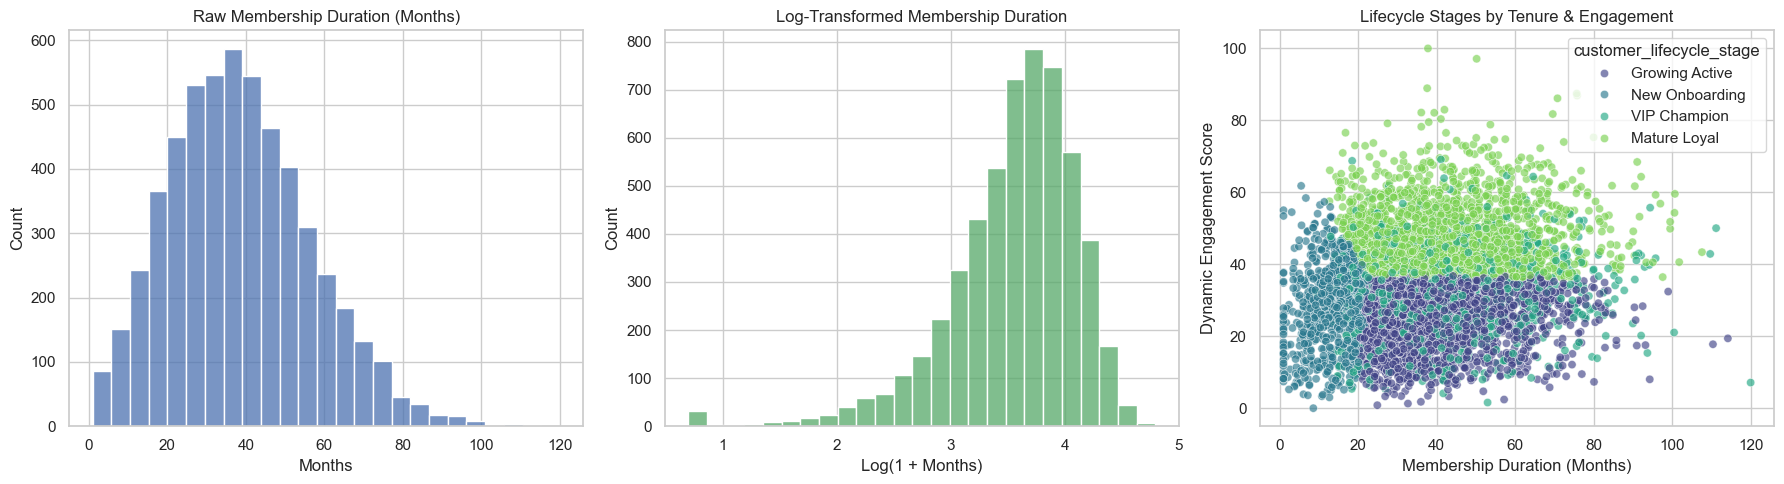

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["membership_duration_months"], bins=25, ax=axes[0], color="#4C72B0")
axes[0].set_title("Raw Membership Duration (Months)")
axes[0].set_xlabel("Months")

sns.histplot(df["log_membership_duration"], bins=25, ax=axes[1], color="#55A868")
axes[1].set_title("Log-Transformed Membership Duration")
axes[1].set_xlabel("Log(1 + Months)")

sns.scatterplot(
    data=df, x="membership_duration_months", y="dynamic_engagement_score",
    hue="customer_lifecycle_stage", palette="viridis", alpha=0.65, ax=axes[2]
)
axes[2].set_title("Lifecycle Stages by Tenure & Engagement")
axes[2].set_xlabel("Membership Duration (Months)")
axes[2].set_ylabel("Dynamic Engagement Score")

plt.tight_layout()
plt.show()

In [10]:
df.to_csv("cleaned_day7.csv", index=False)
print("Saved dataset to cleaned_day7.csv")

Saved dataset to cleaned_day7.csv
